### MECH 5005F | RFP-02 Launch Site Optimizer

Revision 03 · DJI Matrice 400 + Zenmuse L3 · Natadesleen Lake

Compare a single operating base at LZ-01 at the Highway 37 parking lot, LZ-02 through LZ-04 along the Natadesleen Trail, LZ-05 at the trail terminus, or LZ-06 at the hypothetical boat location. Rank plans by **fewest field days**, then **lowest total elapsed field time**. The boat is shown for comparison and is excluded from the default ranking.

Place rfp02_config.py beside this notebook, then restart the kernel and run all cells. The four RFP corners and the points digitized from concept slide 11 are embedded. Results are for a course planning scenario.

1. Aircraft and payload inputs

1.1 Manufacturer data and planning assumptions

| Quantity | Value used | Basis |
|---|---:|---|
| M400 with battery | 9.740 kg | DJI M400 specifications |
| L3 and single-gimbal connector | 1.600 + 0.145 kg | DJI L3 specifications |
| TB100 battery | 4.720 kg | DJI M400 specifications |
| M400 + L3 reference endurance | 53 min at 11 m/s | Ideal waypoint endurance from the DJI L3 Operational White Paper §1.3.7 |
| Nominal planning endurance | 45 min before reserve | Rounded down by about 15% from the ideal loaded reference for a first-pass field model |
| Reduced-endurance case | 35 min before reserve | Sensitivity assumption for less favourable field conditions |
| Landing reserve | 25% of planning endurance | Time-budget approximation from revision 01. The nominal airborne budget is 33.75 min |
| Nominal height over mapped surface | 100 m | Planning assumption. Test footprints over a flat-surface height range of 80–120 m |
| LiDAR operating mode | Non-repetitive, 350 kHz, 16 returns, gimbal −90° | DJI white paper Table 2 recommends this combination for general forest. Retain 50% LiDAR sidelap |
| RGB capture | Dual 100 MP JPEG, minimum 1 s between photos | DJI L3 specifications. Use the higher resolution for the RFP's 2.5 cm/pixel target |
| RGB overlap targets | 70% side, 80% forward | DJI L3 User Manual defaults. Apply the side target to one cropped camera footprint as a conservative planning convention |
| Preferred survey and transit speeds | 10 and 12 m/s | Survey speed from the upper end of DJI’s general-forest recommendation, subject to the RGB interval check. Transit speed is a planning input |
| Baseline command-link distance screen | 3.0 km slant | Scenario input inherited from revision 01. It is varied below and requires on-site or terrain-based substantiation |

DJI’s 59-minute headline is from a different payload configuration with the H30T. The timing model uses the L3-specific reference and applies the planning derate and reserve separately. Airborne time serves as a proxy for battery use. The model has no measured energy or battery state-of-charge curves.

[DJI M400 specifications](https://enterprise.dji.com/matrice-400/specs) · [DJI L3 specifications](https://enterprise.dji.com/zenmuse-l3/specs) · [DJI L3 User Manual, pp. 15–16](https://dl.djicdn.com/downloads/Zenmuse_L3/20251104/Zenmuse_L3_User_Manual_v1.0_en.pdf) · [DJI L3 Operational White Paper v1.0, §1.3.7 and Table 2](https://rtk.mx/wp-content/uploads/2026/10/Zenmuse_L3_Operational_White_Paper_v1.0-1.pdf)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Shared inputs, geometry and route solver
from rfp02_config import (
    airborne_endurance_min, area, boat, boat_id, c2_slant_limit_m, climb_descent_min,
    compare, corner_names, corners, fit_errors, gsd_max_cm, height_max_m, island_xy,
    lake_xy, landing_reserve_fraction, lidar_half_fov_deg, lidar_pulse_rate_hz,
    lidar_spacing_limit_m, line_spacing_m, link_screen_cases_m, metres_per_degree,
    origin_ll, parking_id, perimeter, polygon, pulse_density_target_m2,
    pulse_spacing_target_m, reduced_endurance_min, rfp_area_km2, rfp_perimeter_km,
    rgb_camera_width_m, rgb_gsd_target_cm, rgb_min_along_m, rgb_photo_interval_s,
    rgb_sensitivity_overlap, rgb_spacing_limit_m, rgb_speed_limit_mps, site_label, sites,
    slide_terminus_corner_distances_m, survey_speed_mps, takeoff_mass_kg, tb100_kg,
    terminus_id, trail, trail_station, transit_speed_mps, turn_delay_min, usable_flight_min,
)

1.2 Derive the line spacing and survey speed

On a flat surface, use (W_L = 2H	an 40^circ) for LiDAR cross-track width. For one RGB camera, the inner view angle is (	heta_i=22.5^circ-31^circ=-8.5^circ). Crop its outer usable extent at (	heta_o=50^circ) off nadir. The other camera mirrors it. The single-camera cross-track footprint is (W_R=H(	an	heta_o-	an	heta_i)). Evaluate widths at the minimum surface distance and use

$$
s_{max} = minleft[(1-O_{L,s})W_L,;(1-O_{R,s})W_R
ight].
$$

Project the camera's vertical FOV to the ground to get a conservative minimum along-track footprint, (L_{R,min}=2H	an(mathrm{VFOV}/2)min_	heta[cos(	heta-alpha)/cos	heta]), where (alpha=22.5^circ). The front-overlap speed cap is (v_{max}=(1-O_{R,f})L_{R,min}/Delta t).

For GSD, use a pinhole projection at the **maximum** surface distance. Evaluate the largest singular value of the pixel-to-ground Jacobian at the outer cropped corners. This estimates the largest local ground dimension per pixel and includes geometric stretching off nadir. The overlap calculation is a planning approximation. Confirm the route and camera trigger settings in DJI Pilot 2 and verify overlap near shorelines and terrain breaks.

In [2]:
print(f"Configured takeoff mass before additional accessories: {takeoff_mass_kg:.3f} kg")
print(f"Nominal airborne budget: {usable_flight_min:.2f} min after reserve")
print(f"Model uses {line_spacing_m} m maximum line spacing and {survey_speed_mps:.1f} m/s survey speed.")
display(pd.DataFrame([
    ["LiDAR sidelap", lidar_spacing_limit_m, "m maximum spacing"],
    ["RGB sidelap", rgb_spacing_limit_m, "m maximum spacing"],
    ["RGB forward overlap", rgb_speed_limit_mps, "m/s speed cap"],
    ["Modeled RGB forward overlap", 100 * (1 - survey_speed_mps * rgb_photo_interval_s / rgb_min_along_m), "%"],
    ["Worst modeled RGB GSD", gsd_max_cm, "cm/pixel"],
    ["RGB GSD margin", rgb_gsd_target_cm - gsd_max_cm, "cm/pixel"],
], columns=["Check", "Value", "Units"]).round(2))

Configured takeoff mass before additional accessories: 11.485 kg
Nominal airborne budget: 33.75 min after reserve
Model uses 32 m maximum line spacing and 10.0 m/s survey speed.


,Check,Value,Units
0,LiDAR sidelap,67.13,m maximum spacing
1,RGB sidelap,32.19,m maximum spacing
2,RGB forward overlap,10.42,m/s speed cap
3,Modeled RGB forward overlap,80.81,%
4,Worst modeled RGB GSD,2.28,cm/pixel
5,RGB GSD margin,0.22,cm/pixel


2. Site geometry and route

2.1 Reconstruct the survey polygon and launch sites

Use WGS 84 radii of curvature at the site centre to convert the four RFP Appendix A.2 corners to local east and north metres. Compare the result with the approximate RFP area of 2.865 km² and perimeter of 6.869 km. These local coordinates are for the simulation.

Reuse the affine fit from the four corners on concept slide 11 to digitize the portage and estimate launch points. LZ-01 uses the mapped trail junction as the **Highway 37 parking lot proxy**. The terminus is LZ-05 here and is labelled LZ-01 on the concept slide. The fit residual checks the digitization of those four control points. Exact parking and take-off coordinates, separation from traffic and park users, and usable clearing dimensions still need site evidence.

The map uses an approximate shoreline traced from the imagery on concept slide 11. The trace is for display.

In [3]:
print(f"Area: {area/1e6:.3f} km² ({100*(area/rfp_area_km2*1e6-1):+.2f}% vs. RFP)")
print(f"Perimeter: {perimeter/1000:.3f} km ({100*(perimeter/rfp_perimeter_km*1000-1):+.2f}% vs. RFP)")
print(f"Traced portage {trail_station[-1]:.0f} m • maximum map tie-point residual {max(fit_errors):.1f} m")
print("LZ-05 (trail terminus) corner distances versus slide 11 (m)")
print(pd.DataFrame({"estimate": np.linalg.norm(corners - trail[-1], axis=1).round(),
                    "slide": slide_terminus_corner_distances_m}, index=corner_names).to_string())

geo = []
for name, site in sites.items():
    lat, lon = origin_ll + site.xy[::-1] / metres_per_degree
    geo.append([site_label(name), lat, lon, site.walk_m, site.paddle_m,
                max(np.linalg.norm(corners - site.xy, axis=1))])
geometry = pd.DataFrame(geo, columns=["site","latitude","longitude","walk m","paddle m","max corner m"])
print("\n" + geometry.round({"latitude":5, "longitude":5, "walk m":0,
                             "paddle m":0, "max corner m":0}).to_string(index=False))

Area: 2.879 km² (+100500757702684.11% vs. RFP)
Perimeter: 6.885 km (+100234112.19% vs. RFP)
Traced portage 1030 m • maximum map tie-point residual 1.2 m
LZ-05 (trail terminus) corner distances versus slide 11 (m)
   estimate  slide
A    1726.0   1717
B    1434.0   1412
C     814.0    823
D    1235.0   1255

                      site  latitude  longitude  walk m  paddle m  max corner m
LZ-01 · Hwy 37 parking lot  57.47614 -130.22673     0.0       0.0        2331.0
         LZ-02 · Trail 25%  57.47726 -130.23050   258.0       0.0        2100.0
         LZ-03 · Trail 50%  57.47823 -130.23439   515.0       0.0        1887.0
         LZ-04 · Trail 75%  57.47874 -130.23854   773.0       0.0        1726.0
    LZ-05 · Trail terminus  57.47803 -130.24243  1030.0       0.0        1726.0
        LZ-06 · Boat proxy  57.48197 -130.24452  1030.0     456.0        1270.0


2.2 Build survey strips and budget each sortie

Rotate the polygon onto each tested bearing and divide its width into equal bands no wider than (s_{max}). The strip runs through the centre of its band. Use the full along-track extent of the band's intersection with the survey polygon, plus run-in and run-out, to cover sloping polygon edges. The combined RGB and LiDAR widths exceed each band width under the flat-surface assumptions. This is a geometric envelope check. Individual LiDAR returns, reconstruction-quality edge overlap, and canopy and shoreline occlusion are outside this calculation.

For each ordered route, compute transit, acquisition, turns, climb and descent. Split the route into battery-limited sorties and schedule them into field days. The elapsed-time objective includes portage (where applicable), setup and packdown, control, delay allowance, turnaround and field QA. The battery inventory is a daily cap with fresh batteries at the start of each day. The model assumes one full crew carries the required field equipment in the specified number of portage waves, straight transit and connectors, and no field charging.

In [4]:
# The route and sortie solver is imported from rfp02_config.py.


3. Nominal trade study

3.1 Rank candidate sites and plot the route

Compare all bases under the same sensor settings, flight-budget assumptions and 3 km slant-distance screen. Maximum slant distance includes strip extensions. Straight connectors lie within the maximum distance of their endpoints under the flat-height assumption. A shorter geometric distance can help the radio link. The screen does not model vegetation masking, terrain or interference.

Set the three switches at the top of the map cell. You can rerun that cell on its own after changing a switch.

In [5]:
results, plans = compare(line_spacing_m, airborne_endurance_min)
display(results.round(2))
eligible = results[results.selectable & results.days.notna()]
selected = eligible.iloc[0].site if len(eligible) else None
print(f"Selected for this scenario: {site_label(selected) if selected else 'No selectable site fits'}")

,site,location,selectable,access_min,days,field_h,sorties,flight_min,peak_day_h,bearing_deg,slant_m,status
0,LZ-01,Hwy 37 parking lot,True,0.00,1,6.17,7,200.93,6.17,120,2355.50,Fits scenario
1,LZ-02,Trail 25%,True,12.36,1,6.31,7,197.32,6.31,120,2124.37,Fits scenario
2,LZ-03,Trail 50%,True,24.73,1,6.48,7,195.00,6.48,120,1910.26,Fits scenario
3,LZ-04,Trail 75%,True,37.09,1,6.71,7,196.57,6.71,120,1747.89,Fits scenario
4,LZ-05,Trail terminus,True,49.46,1,6.77,6,195.04,6.77,15,1750.36,Fits scenario
5,LZ-06,Boat proxy,False,93.15,1,7.75,7,202.58,7.75,120,1289.70,Fits scenario


Selected for this scenario: LZ-01 · Hwy 37 parking lot


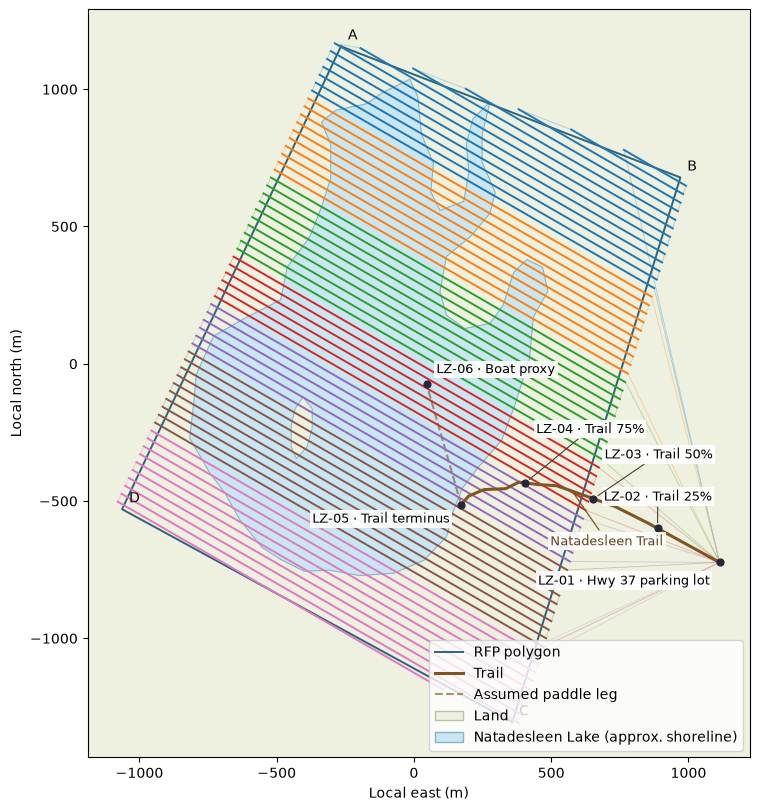

In [6]:
# Map controls
show_lz_prefix = True
show_trail_label = True
show_land_water = True

from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
legend_background = []
if show_land_water:
    land_color, water_color = "#eef1df", "#c9e7f2"
    ax.set_facecolor(land_color)
    ax.fill(*lake_xy.T, color=water_color, ec="#82b6c5", lw=0.8, zorder=0.5)
    ax.fill(*island_xy.T, color=land_color, ec="#82b6c5", lw=0.7, zorder=0.6)
    legend_background = [
        Patch(facecolor=land_color, edgecolor="#b7c1a7", label="Land"),
        Patch(facecolor=water_color, edgecolor="#82b6c5", label="Natadesleen Lake (approx. shoreline)"),
    ]
ax.plot(*polygon.T, color="#2b647b", lw=1.4, label="RFP polygon")
ax.plot(*trail.T, color="#805522", lw=2.2, zorder=4, label="Trail")
ax.plot(*np.vstack([trail[-1], boat]).T, "--", color="#805522", alpha=0.65,
        label="Assumed paddle leg")
for label, corner in zip(corner_names, corners):
    ax.annotate(label, corner, xytext=(5, 5), textcoords="offset points")
trail_label_offsets = {"LZ-02": (39, 20), "LZ-03": (8, 29), "LZ-04": (8, 36)}
for site_id, site in sites.items():
    ax.scatter(*site.xy, color="#27263c", s=24, zorder=5)
    offset = trail_label_offsets.get(site_id, {
        parking_id: (-7, -16), terminus_id: (-8, -13), boat_id: (7, 8),
    }.get(site_id, (7, 8)))
    alignment = "right" if site_id in {parking_id, "LZ-02", terminus_id} else "left"
    leader = dict(arrowstyle="-", color="#464139", lw=0.8, shrinkA=1, shrinkB=4)
    ax.annotate(site_label(site_id, show_lz_prefix), site.xy, xytext=offset,
                textcoords="offset points", ha=alignment, fontsize=9, zorder=6,
                arrowprops=leader if site_id in trail_label_offsets else None,
                bbox=dict(facecolor="white", alpha=0.92, edgecolor="none", pad=1.5))
if show_trail_label:
    station = 0.58 * trail_station[-1]
    trail_anchor = [np.interp(station, trail_station, trail[:, axis]) for axis in range(2)]
    ax.annotate("Natadesleen Trail", trail_anchor, xytext=(25, -39),
                textcoords="offset points", ha="center", fontsize=9, color="#68441b",
                zorder=6, bbox=dict(facecolor="white", alpha=0.88, edgecolor="none", pad=1.5),
                arrowprops=dict(arrowstyle="-", color="#805522", lw=0.9))
if selected:
    choice = plans[selected]
    route = choice["route"]
    base = sites[selected].xy
    for day_number, day in enumerate(choice["result"][2], 1):
        for sortie_number, (start, end, flight) in enumerate(day, 1):
            color = plt.cm.tab10((sortie_number-1 + day_number-1) % 10)
            lines = route[start:end]
            path = np.vstack([base,lines.reshape(-1,2),base])
            ax.plot(*path.T, color=color, lw=0.65, alpha=0.3)
            for strip in lines:
                ax.plot(*strip.T, color=color, lw=1.4)
            assert flight <= airborne_endurance_min * (1-landing_reserve_fraction) + 1e-9
map_site = site_label(selected, show_lz_prefix) if selected else "geometry only"
ax.set(
    # title=f"Candidate bases and planned survey route | {map_site}",
       xlabel="Local east (m)", ylabel="Local north (m)", aspect="equal")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + legend_background, loc="lower right")
plt.show()


3.2 Inspect the sortie schedule and cross-check distance and time

Separate acquisition from repositioning. Independently sum the plotted legs and allowances and verify their agreement with the optimizer's sortie durations. Use polygon area divided by actual strip spacing as an order-of-magnitude check on straight acquisition distance for a single grid. The actual distance also includes edge coverage and run-in/out.

In [7]:
if selected:
    day_rows = []
    for day_number, day in enumerate(plans[selected]["result"][2], 1):
        for sortie_number, (first, last, flight) in enumerate(day, 1):
            lines = route[first:last]
            path = np.vstack([base, lines.reshape(-1, 2), base])
            leg_dist_m = np.linalg.norm(np.diff(path, axis=0), axis=1)
            survey_dist_m = leg_dist_m[1::2].sum()
            transit_dist_m = leg_dist_m[::2].sum()
            time_check = (survey_dist_m / (60 * survey_speed_mps)
                          + transit_dist_m / (60 * transit_speed_mps)
                          + (len(lines) - 1) * turn_delay_min + climb_descent_min)
            assert np.isclose(flight, time_check)
            day_rows.append([day_number, sortie_number, first + 1, last, survey_dist_m / 1000,
                             transit_dist_m / 1000, flight, usable_flight_min - flight])

    sortie_table = pd.DataFrame(day_rows, columns=[
        "Day", "Sortie", "First segment", "Last segment", "Survey km", "Transit km",
        "Flight min", "Margin beyond reserve min",
    ])
    assert sortie_table["First segment"].iloc[0] == 1
    assert sortie_table["Last segment"].iloc[-1] == len(route)
    assert np.array_equal(sortie_table["First segment"].to_numpy()[1:],
                          sortie_table["Last segment"].to_numpy()[:-1] + 1)
    display(sortie_table.round(2))

    peak_sets_used = int(sortie_table.groupby("Day").size().max())
    print(f"Peak daily battery requirement: {peak_sets_used} sets "
          f"({(peak_sets_used - 1) * tb100_kg:.1f} kg of spares, one battery installed).")
    print(f"Survey distance: {sortie_table['Survey km'].sum():.1f} km. "
          f"Single-grid area/spacing check: about {area/line_spacing_m/1000:.1f} km before edge extensions.")

,Day,Sortie,First segment,Last segment,Survey km,Transit km,Flight min,Margin beyond reserve min
0,1,1,1,13,14.69,3.37,32.87,0.88
1,1,2,14,23,14.64,2.05,30.66,3.09
2,1,3,24,33,15.11,1.60,30.81,2.94
3,1,4,34,39,9.29,1.24,20.21,13.54
4,1,5,40,45,9.45,1.23,20.46,13.29
5,1,6,46,55,16.13,1.56,32.44,1.31
6,1,7,56,65,16.28,2.13,33.49,0.26


Peak daily battery requirement: 7 sets (28.3 kg of spares, one battery installed).
Survey distance: 95.6 km. Single-grid area/spacing check: about 90.0 km before edge extensions.


3.3 Screen LiDAR sampling and relate it to the RFP

Approximate the **emitted** single-pass pulse density by (f/(vW_L)), using the widest flat-surface swath at 120 m for a conservative mean over that swath. The reciprocal square root of the resulting density gives an equivalent spacing for uniform sampling. Actual sampling within the non-repetitive pattern varies with scan angle and detection. Multiple returns from one pulse cannot be counted as separate pulses for PR-01. Use Pilot 2's point-cloud output estimate and check field density and accuracy in post-processing.

In [8]:
widest_lidar_swath_m = 2 * height_max_m * np.tan(np.radians(lidar_half_fov_deg))
emitted_pulse_density = lidar_pulse_rate_hz / (survey_speed_mps * widest_lidar_swath_m)
equivalent_pulse_spacing_m = 1 / np.sqrt(emitted_pulse_density)
capture_fraction_percent = 100 * max(pulse_density_target_m2, 1 / pulse_spacing_target_m**2) / emitted_pulse_density
print(f"Mean emitted pulses: {emitted_pulse_density:.0f} pulses/m² at the widest modeled LiDAR swath")
print(f"Equivalent uniform emitted-pulse spacing: {equivalent_pulse_spacing_m:.3f} m")
print(f"At least {capture_fraction_percent:.1f}% distinct-pulse detection would be needed "
      "on average to satisfy both numerical PR-01 sampling targets under a uniform-density approximation.")

Mean emitted pulses: 174 pulses/m² at the widest modeled LiDAR swath
Equivalent uniform emitted-pulse spacing: 0.076 m
At least 4.7% distinct-pulse detection would be needed on average to satisfy both numerical PR-01 sampling targets under a uniform-density approximation.


| RFP item | What the model establishes |
|---|---|
| MR-01, MR-02, PR-04 | The nominal flat-surface envelopes are planned across the polygon. Separate terrestrial and shoreline coverage, avoidable gaps, water voids, and surface-specific image matching need checks against the site or processed data. |
| MR-03, MR-04, OR-01 | One campaign with paired LiDAR/RGB acquisition on the survey strips. Sortie count, time and field day estimates are conditional on the inputs. |
| PR-01, PR-02 | The emitted-pulse screen supports the selected settings for planning. Actual density and spacing, ground returns under canopy, and LiDAR vertical accuracy require evidence. DJI's 120 m system-accuracy benchmark uses linear scanning and exposed hard ground, which differ from the forest case here. |
| PR-03 | The pinhole projection estimates GSD. The 0.05 m RGB horizontal RMSE requirement needs independent checkpoints. |

4. Sensitivity and launch-site decision

4.1 Check less favourable aircraft and overlap assumptions

Rerank with the same candidate sites. Test shorter endurance, tighter RGB overlap (75% side), and the combination. The setup and access estimates are shared with the nominal run.

In [9]:
tighter_spacing_m = int(min(lidar_spacing_limit_m, rgb_camera_width_m * (1 - rgb_sensitivity_overlap)))
scenarios = [
    ("Nominal", line_spacing_m, airborne_endurance_min),
    ("Reduced endurance", line_spacing_m, reduced_endurance_min),
    ("75% RGB sidelap", tighter_spacing_m, airborne_endurance_min),
    ("Both changes", tighter_spacing_m, reduced_endurance_min),
]
scenario_rows = []
for label, spacing, endurance in scenarios:
    table = results if label == "Nominal" else compare(spacing, endurance)[0]
    candidates = table[table.selectable & table.days.notna()]
    road_row = table.loc[table.site == parking_id].iloc[0]
    lz_row = table.loc[table.site == terminus_id].iloc[0]
    winner = candidates.iloc[0] if len(candidates) else None
    scenario_rows.append([label, spacing, endurance * (1 - landing_reserve_fraction),
                          site_label(winner.site) if winner is not None else "None",
                          winner.days if winner is not None else np.nan,
                          winner.field_h if winner is not None else np.nan,
                          road_row.days, road_row.sorties, road_row.field_h,
                          lz_row.days, lz_row.sorties, lz_row.field_h])

scenario_table = pd.DataFrame(scenario_rows, columns=[
    "Scenario", "Spacing m", "Usable flight min", "Top site", "Top site days", "Top site field h",
    "LZ-01 days", "LZ-01 sorties",
    "LZ-01 field h", "LZ-05 days", "LZ-05 sorties", "LZ-05 field h",
])
display(scenario_table.round(2))

,Scenario,Spacing m,Usable flight min,Top site,Top site days,Top site field h,LZ-01 days,LZ-01 sorties,LZ-01 field h,LZ-05 days,LZ-05 sorties,LZ-05 field h
0,Nominal,32,33.75,LZ-01 · Hwy 37 parking lot,1,6.17,1,7,6.17,1,6,6.77
1,Reduced endurance,32,26.25,LZ-01 · Hwy 37 parking lot,1,6.56,1,9,6.56,1,9,7.35
2,75% RGB sidelap,26,33.75,LZ-01 · Hwy 37 parking lot,1,7.03,1,8,7.03,1,8,7.79
3,Both changes,26,26.25,LZ-03 · Trail 50%,1,7.75,2,11,9.61,2,10,11.05


4.2 Find when the distance screen changes the recommendation

Keep the nominal sensor and endurance settings. Change only the assumed allowable slant distance and rerank. A trail location can score well only if it has a usable clearing for the operation. Losing the road on the screen does not establish that an intermediate trail location is operationally available.

In [10]:
link_rows = []
for limit in sorted({*link_screen_cases_m, c2_slant_limit_m}):
    table = results if limit == c2_slant_limit_m else compare(
        line_spacing_m, airborne_endurance_min, slant_limit=limit
    )[0]
    candidates = table[table.selectable & table.days.notna()]
    road_fits = table.loc[table.site == parking_id, "days"].notna().iloc[0]
    lz_fits = table.loc[table.site == terminus_id, "days"].notna().iloc[0]
    row = candidates.iloc[0] if len(candidates) else None
    link_rows.append([limit, road_fits, lz_fits, site_label(row.site) if row is not None else "None",
                      row.field_h if row is not None else np.nan])
link_table = pd.DataFrame(link_rows, columns=[
    "Slant screen m", "LZ-01 fits", "LZ-05 fits", "Top site", "Field h",
])
display(link_table.round(2))

,Slant screen m,LZ-01 fits,LZ-05 fits,Top site,Field h
0,1750,False,True,LZ-04 · Trail 75%,6.71
1,1850,False,True,LZ-04 · Trail 75%,6.71
2,2000,False,True,LZ-03 · Trail 50%,6.48
3,2200,False,True,LZ-02 · Trail 25%,6.31
4,2350,True,True,LZ-01 · Hwy 37 parking lot,6.24
5,2400,True,True,LZ-01 · Hwy 37 parking lot,6.17
6,3000,True,True,LZ-01 · Hwy 37 parking lot,6.17


4.3 Interpret the result

Use the nominal ranking for elapsed field time and the distance sweep to assess how much shorter the screened link can be before the ranking changes. Establish launch area suitability, access and visitor separation, terrain/trees along the routes, and command-link performance before carrying the recommendation into the final mission simulation. The site positions and daily setup logistics are estimates.

In [11]:
road = results.loc[results.site == parking_id].iloc[0]
terminus = results.loc[results.site == terminus_id].iloc[0]
if selected and pd.notna(road.field_h) and pd.notna(terminus.field_h):
    hwy_advantage_min = 60 * (terminus.field_h - road.field_h)
    print(f"Nominal winner: {site_label(selected)}. LZ-01 field-time advantage over LZ-05: "
          f"{hwy_advantage_min:+.0f} min.")
    print(f"LZ-01: {road.slant_m/1000:.2f} km maximum slant distance on its nominal route. "
          f"LZ-05: {terminus.slant_m/1000:.2f} km.")

Nominal winner: LZ-01 · Hwy 37 parking lot. LZ-01 field-time advantage over LZ-05: +37 min.
LZ-01: 2.36 km maximum slant distance on its nominal route. LZ-05: 1.75 km.
